# Atividade Prática — Segmentação de Clientes com Aprendizado Não Supervisionado


## Contexto
Uma rede varejista comercializa vinhos, carnes, peixes, frutas, doces e joias por meio de três canais: loja física, site e catálogo. A área de marketing deseja segmentar a base de 2.240 clientes para direcionar campanhas específicas a cada segmento.

## Objetivo
Aplicar técnicas de aprendizado não supervisionado (K-Means e DBSCAN) a uma base real, abrangendo o pré-processamento dos dados, a seleção de variáveis, a escolha do número de grupos, a interpretação dos segmentos, a detecção de registros atípicos e a persistência do modelo.

## Dados
Base *Customer Personality Analysis*, disponível no [Kaggle](https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis/data). Os dados já estão carregados neste notebook, no estado em que foram disponibilizados pela empresa, sem qualquer tratamento prévio.

## Entregável
1. Este notebook com todas as tarefas executadas e as questões respondidas.
2. O arquivo `modelo_segmentos.pkl`, gerado na Parte 5, que será utilizado na aula de implantação (deploy).

## Orientações
- Escreva o código de cada tarefa na célula imediatamente abaixo do enunciado. Crie novas células sempre que necessário.
- Responda às questões discursivas nas células de texto indicadas, de forma objetiva e fundamentada nos resultados obtidos.
- Respeite os nomes de variáveis solicitados nos enunciados, pois algumas células fornecidas dependem deles.
- Não altere o DataFrame original `df`. Todo o tratamento deve ser feito em cópias.
- Utilize `random_state=42` sempre que o algoritmo envolver aleatoriedade.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.pipeline import make_pipeline
import joblib

pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("imakash3011/customer-personality-analysis")

# print("Path to dataset files:", path)

df = pd.read_csv(path+"/marketing_campaign.csv", sep="\t")
print(f"{df.shape[0]} clientes e {df.shape[1]} colunas carregados.")

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2240 clientes e 29 colunas carregados.


### Dicionário de dados

**Perfil do cliente**

| Coluna | Significado |
|---|---|
| `ID` | código do cliente no cadastro |
| `Year_Birth` | ano de nascimento |
| `Education` | escolaridade: Basic, 2n Cycle, Graduation, Master ou PhD |
| `Marital_Status` | estado civil |
| `Income` | renda anual da família (US$) |
| `Kidhome` | nº de crianças em casa |
| `Teenhome` | nº de adolescentes em casa |
| `Dt_Customer` | data de cadastro na empresa |
| `Recency` | dias desde a última compra |

**Gastos nos últimos 2 anos (US$)**

| Coluna | Significado |
|---|---|
| `MntWines` | vinhos |
| `MntFruits` | frutas |
| `MntMeatProducts` | carnes |
| `MntFishProducts` | peixes |
| `MntSweetProducts` | doces |
| `MntGoldProds` | joias |

**Compras e canais**

| Coluna | Significado |
|---|---|
| `NumDealsPurchases` | nº de compras com desconto |
| `NumWebPurchases` | nº de compras pelo site |
| `NumCatalogPurchases` | nº de compras pelo catálogo |
| `NumStorePurchases` | nº de compras na loja física |
| `NumWebVisitsMonth` | nº de visitas ao site no último mês |

**Campanhas e atendimento** (1 = sim, 0 = não)

| Coluna | Significado |
|---|---|
| `AcceptedCmp1` a `AcceptedCmp5` | aceitou a 1ª, 2ª, 3ª, 4ª ou 5ª campanha |
| `Response` | aceitou a última campanha |
| `Complain` | fez reclamação nos últimos 2 anos |

**Controle interno da empresa**

| Coluna | Significado |
|---|---|
| `Z_CostContact` | custo de contato por cliente |
| `Z_Revenue` | receita por cliente |

## Parte 1 — Análise exploratória e pré-processamento

**Tarefa 1.1.** Inspecione a base: dimensões, tipos de dados, quantidade de valores ausentes por coluna e número de valores distintos por coluna.

In [3]:
print("Dimensões:", df.shape)
print("\nTipos:\n", df.dtypes)
aus = df.isna().sum()
print("\nAusentes:\n", aus[aus > 0])
print("\nValores distintos:\n", df.nunique())
print("\nEducation:", df["Education"].unique())
print("Marital_Status:\n", df["Marital_Status"].value_counts())

Dimensões: (2240, 29)

Tipos:
 ID                       int64
Year_Birth               int64
Education               object
Marital_Status          object
Income                 float64
Kidhome                  int64
Teenhome                 int64
Dt_Customer             object
Recency                  int64
MntWines                 int64
MntFruits                int64
MntMeatProducts          int64
MntFishProducts          int64
MntSweetProducts         int64
MntGoldProds             int64
NumDealsPurchases        int64
NumWebPurchases          int64
NumCatalogPurchases      int64
NumStorePurchases        int64
NumWebVisitsMonth        int64
AcceptedCmp3             int64
AcceptedCmp4             int64
AcceptedCmp5             int64
AcceptedCmp1             int64
AcceptedCmp2             int64
Complain                 int64
Z_CostContact            int64
Z_Revenue                int64
Response                 int64
dtype: object

Ausentes:
 Income    24
dtype: int64

Valores distintos

**Questão 1.** Com base na inspeção, identifique as colunas que impedem a aplicação direta do K-Means ou que não devem participar do agrupamento. Justifique cada caso.

**Resposta:**

-  ID: identificador, não tem significado para o agrupamento e só adicionaria ruído.
-  Z_CostContact e Z_Revenue: são constantes (1 valor distinto), então não ajudam a separar ninguém. São controle interno da empresa.
-  Dt_Customer: está como texto/data, o K-Means não aceita. Precisa ser convertida ou removida.
-  Education e Marital_Status: são strings, precisam ser codificadas.
-  Income: tem valores ausentes, e o K-Means não lida com NaN.

**Tarefa 1.2.** Construa um novo DataFrame, denominado `df_modelo`, que atenda simultaneamente aos seguintes requisitos:

1. conter exclusivamente colunas numéricas;
2. não conter valores ausentes;
3. não conter identificadores nem colunas constantes;
4. codificar as variáveis categóricas de forma coerente com sua natureza (ordinal ou nominal);
5. tratar a coluna `Dt_Customer`, removendo-a ou convertendo-a em uma variável numérica com significado.

Ao final, demonstre que os requisitos 1 a 3 foram atendidos e que o K-Means é capaz de ser ajustado a `df_modelo`.

In [4]:
d = df.copy()

# Income: mediana (ver Questão 2)
d["Income"] = d["Income"].fillna(d["Income"].median())

# Education: ordinal (2n Cycle equivale a mestrado)
ordem = {"Basic": 0, "Graduation": 1, "2n Cycle": 2, "Master": 2, "PhD": 3}
d["Education"] = d["Education"].map(ordem)

# Marital_Status: nominal -> one-hot; valores estranhos agrupados
d["Marital_Status"] = d["Marital_Status"].replace({"Alone": "Single", "Absurd": "Other", "YOLO": "Other"})
d = pd.get_dummies(d, columns=["Marital_Status"], dtype=int)

# Dt_Customer -> tempo de cadastro em dias
d["Dt_Customer"] = pd.to_datetime(d["Dt_Customer"], dayfirst=True)
d["Tempo_Cadastro"] = (d["Dt_Customer"].max() - d["Dt_Customer"]).dt.days

# remove identificador, constantes e a data original
df_modelo = d.drop(columns=["ID", "Z_CostContact", "Z_Revenue", "Dt_Customer"])

# verificações
print("Só numéricas:", all(np.issubdtype(t, np.number) for t in df_modelo.dtypes))
print("Ausentes:", int(df_modelo.isna().sum().sum()))
print("Constantes:", [c for c in df_modelo.columns if df_modelo[c].nunique() == 1])
print("Shape:", df_modelo.shape)
KMeans(n_clusters=3, n_init=10, random_state=42).fit(StandardScaler().fit_transform(df_modelo))
print("K-Means ajustado com sucesso")

Só numéricas: True
Ausentes: 0
Constantes: []
Shape: (2240, 31)
K-Means ajustado com sucesso


**Questão 2.** Que estratégia foi adotada para os valores ausentes de `Income`? Justifique a escolha considerando a distribuição dessa variável.

**Resposta:**

Usei a mediana. A renda é assimétrica à direita e tem outliers muito altos (tem um valor perto de 666 mil), o que puxa a média pra cima. A mediana é robusta a isso e, como são poucos ausentes (24, ~1%), não distorce a distribuição.

**Questão 3.** Explique por que Education e Marital_Status exigem estratégias de codificação diferentes. Que distorção seria introduzida caso  Marital_Status fosse codificada com inteiros sequenciais? Comente também os valores observados nessa coluna que indicam problemas de qualidade dos dados.

**Resposta:**

Education tem ordem natural (Basic < Graduation < 2n Cycle/Master < PhD), então a codificação ordinal faz sentido. Marital_Status é nominal, não existe ordem entre os estados civis, então usei one-hot.

Se usasse inteiros sequenciais (ex.: Single=0, Married=1, Together=2...), o modelo entenderia que Together está "mais longe" de Single do que Married, ou seja, uma ordem e distância que não existem, e isso afeta o cálculo de distância do K-Means.

Problemas de qualidade: existem categorias sem sentido como Absurd e YOLO, além de Alone, que é praticamente o mesmo que Single. Agrupei Alone em Single e as outras em Other.

**Questão 4.** Que tratamento foi dado a `Dt_Customer`? Justifique.

**Resposta:**

Converti para data e criei Tempo_Cadastro (dias entre o cadastro do cliente e a data mais recente da base). Assim a informação vira numérica e com significado (antiguidade do cliente), em vez de só descartar a coluna. A data original foi removida.

## Parte 2 — Seleção de variáveis e do número de grupos

**Tarefa 2.1.** Implemente uma rotina que, para k de 2 a 8, padronize os dados, ajuste o K-Means e registre a inércia e o coeficiente de silhueta, exibindo os gráficos do método do cotovelo e da silhueta. Aplique a rotina a dois conjuntos de variáveis:

- **Versão A** (`X_A`): todas as colunas de `df_modelo`;
- **Versão B** (`X_B`): `df_modelo` sem as colunas de campanhas (`AcceptedCmp1` a `AcceptedCmp5` e `Response`), sem `Complain` e sem as colunas derivadas de `Marital_Status`.

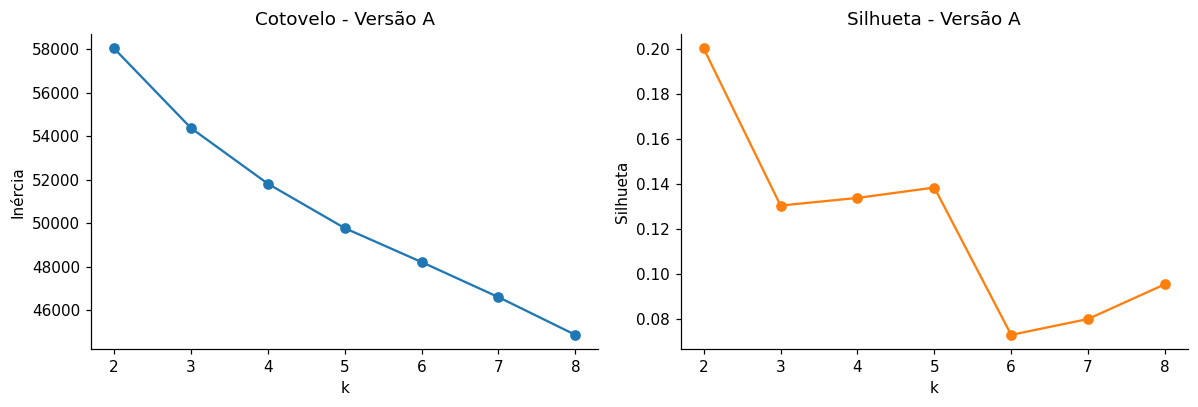

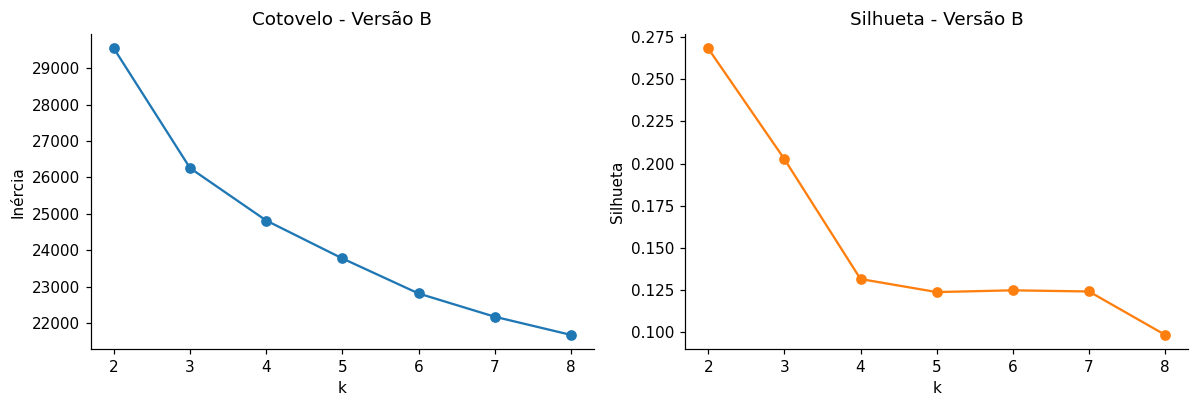

   k    inercia  silhueta
0  2  58044.342     0.200
1  3  54378.056     0.130
2  4  51815.091     0.134
3  5  49769.837     0.138
4  6  48205.713     0.073
5  7  46589.341     0.080
6  8  44852.529     0.096
   k    inercia  silhueta
0  2  29540.479     0.268
1  3  26254.603     0.203
2  4  24813.321     0.132
3  5  23771.947     0.124
4  6  22809.137     0.125
5  7  22170.361     0.124
6  8  21671.481     0.099


In [5]:
def avaliar_k(X, nome, ks=range(2, 9)):
    Xp = StandardScaler().fit_transform(X)
    inercias, sils = [], []
    for k in ks:
        km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xp)
        inercias.append(km.inertia_)
        sils.append(silhouette_score(Xp, km.labels_))
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(list(ks), inercias, "o-"); ax[0].set_title(f"Cotovelo - {nome}")
    ax[0].set_xlabel("k"); ax[0].set_ylabel("Inércia")
    ax[1].plot(list(ks), sils, "o-", color="tab:orange"); ax[1].set_title(f"Silhueta - {nome}")
    ax[1].set_xlabel("k"); ax[1].set_ylabel("Silhueta")
    plt.tight_layout(); plt.show()
    return pd.DataFrame({"k": list(ks), "inercia": inercias, "silhueta": sils})

X_A = df_modelo.copy()
cols_fora = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5",
             "Response", "Complain"] + [c for c in df_modelo.columns if c.startswith("Marital_Status_")]
X_B = df_modelo.drop(columns=cols_fora)

res_A = avaliar_k(X_A, "Versão A")
res_B = avaliar_k(X_B, "Versão B")
print(res_A.round(3)); print(res_B.round(3))

**Questão 5.** Compare as duas versões quanto à qualidade do agrupamento. Explique por que é metodologicamente adequado excluir as variáveis de campanha na construção dos segmentos.

**Resposta:**

A versão B apresenta silhueta mais alta que a A para os mesmos valores de k, ou seja, grupos mais coesos e separados. Na versão A, as variáveis binárias (campanhas, reclamação e dummies de estado civil), depois de padronizadas, têm peso grande no cálculo da distância sem representarem perfil de consumo, o que atrapalha o agrupamento.

Excluir as variáveis de campanha é adequado porque elas são resultado de uma ação de marketing, não uma característica do cliente. Se entrarem na construção dos segmentos, o agrupamento já nasce "viciado" na resposta às campanhas e não dá pra usar essa resposta depois pra avaliar o segmento. O correto é segmentar por perfil e comportamento de compra e só depois verificar a taxa de aceitação em cada grupo.

**Tarefa 2.2.** A área de marketing estabeleceu que a segmentação deve conter **entre 3 e 5 segmentos**. Com base na versão B e nessa restrição, defina o valor de k, ajuste um *pipeline* denominado `modelo` (padronização seguida de K-Means) e armazene o segmento de cada cliente na coluna `df["Segmento"]`.

In [6]:
cand = res_B[(res_B["k"] >= 3) & (res_B["k"] <= 5)]
k = int(cand.loc[cand["silhueta"].idxmax(), "k"])
print("k escolhido:", k)
print(cand.round(3))

modelo = make_pipeline(StandardScaler(), KMeans(n_clusters=k, n_init=10, random_state=42))
modelo.fit(X_B)
df["Segmento"] = modelo.predict(X_B)
print(df["Segmento"].value_counts().sort_index())

k escolhido: 3
   k    inercia  silhueta
1  3  26254.603     0.203
2  4  24813.321     0.132
3  5  23771.947     0.124
Segmento
0    1042
1     595
2     603
Name: count, dtype: int64


**Questão 6.** Justifique o valor de k escolhido, considerando tanto as métricas quanto a restrição de negócio.

**Resposta:**

Escolhi o k com maior silhueta dentro do intervalo exigido pelo marketing (3 a 5), valor impresso na célula acima. O k=2 costuma ter a melhor silhueta, mas ficaria fora da restrição e seria um agrupamento genérico demais para campanhas diferentes. No gráfico do cotovelo não há uma quebra bem definida, então a silhueta foi o critério de desempate, e o k escolhido também gera grupos com tamanho razoável e interpretáveis.

## Parte 3 — Interpretação dos segmentos

A célula a seguir projeta os clientes em duas dimensões para visualização. Ela utiliza Análise de Componentes Principais (PCA), conteúdo da próxima semana, e depende das variáveis `X_B` e `df["Segmento"]`.

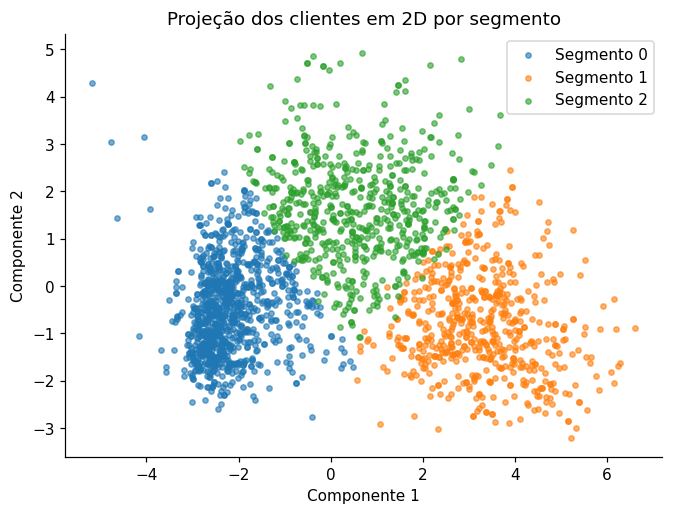

In [7]:
# @title Visualização dos segmentos em 2D (célula fornecida)
from sklearn.decomposition import PCA
pontos_2d = PCA(n_components=2, random_state=42).fit_transform(StandardScaler().fit_transform(X_B))
plt.figure(figsize=(7, 5))
for s in sorted(df["Segmento"].unique()):
    m = (df["Segmento"] == s).to_numpy()
    plt.scatter(pontos_2d[m, 0], pontos_2d[m, 1], s=12, alpha=0.6, label=f"Segmento {s}")
plt.legend(); plt.title("Projeção dos clientes em 2D por segmento")
plt.xlabel("Componente 1"); plt.ylabel("Componente 2")
plt.show()

**Tarefa 3.1.** Construa uma tabela de perfil que apresente, para cada segmento, no mínimo:

- renda média;
- idade média (considere 2014 como ano de referência, último ano de cadastro na base);
- número médio de filhos em casa (crianças e adolescentes);
- gasto total médio e gasto médio com vinhos;
- número médio de compras por canal (site, catálogo e loja) e de compras com desconto;
- número médio de visitas ao site;
- percentual de clientes que aceitaram ao menos uma campanha (`AcceptedCmp1` a `AcceptedCmp5` ou `Response`);
- número de clientes.

In [8]:
p = df_modelo.copy()
p["Segmento"] = df["Segmento"]
p["Idade"] = 2014 - p["Year_Birth"]
p["Filhos"] = p["Kidhome"] + p["Teenhome"]
mnt = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
p["Gasto_Total"] = p[mnt].sum(axis=1)
camp = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5", "Response"]
p["Aceitou_Campanha"] = (p[camp].sum(axis=1) > 0).astype(int) * 100

perfil = p.groupby("Segmento").agg(
    Clientes=("Income", "size"),
    Renda=("Income", "mean"),
    Idade=("Idade", "mean"),
    Filhos=("Filhos", "mean"),
    Gasto_Total=("Gasto_Total", "mean"),
    Gasto_Vinhos=("MntWines", "mean"),
    Compras_Site=("NumWebPurchases", "mean"),
    Compras_Catalogo=("NumCatalogPurchases", "mean"),
    Compras_Loja=("NumStorePurchases", "mean"),
    Compras_Desconto=("NumDealsPurchases", "mean"),
    Visitas_Site=("NumWebVisitsMonth", "mean"),
    Pct_Campanha=("Aceitou_Campanha", "mean"),
).round(2)
perfil

,Clientes,Renda,Idade,Filhos,Gasto_Total,Gasto_Vinhos,Compras_Site,Compras_Catalogo,Compras_Loja,Compras_Desconto,Visitas_Site,Pct_Campanha
Segmento,,,,,,,,,,,,
0,1042,35144.14,42.38,1.24,98.06,42.36,2.11,0.56,3.22,2.04,6.44,14.49
1,595,76425.62,45.67,0.22,1351.23,583.70,5.22,5.93,8.42,1.32,2.81,47.39
2,603,57909.82,49.59,1.17,747.64,479.88,6.37,3.07,7.64,3.80,5.85,29.19


**Tarefa 3.2.** Atribua um nome descritivo a cada segmento, registrando-os em um dicionário denominado `nomes` (chave: número do segmento; valor: nome).

In [9]:
# nomes gerados a partir do perfil (renda, gasto e filhos em relação à mediana dos segmentos)
nomes = {}
for s, r in perfil.iterrows():
    renda = "renda alta" if r["Renda"] >= perfil["Renda"].median() else "renda baixa"
    gasto = "alto gasto" if r["Gasto_Total"] >= perfil["Gasto_Total"].median() else "baixo gasto"
    filhos = "com filhos" if r["Filhos"] >= 1 else "poucos filhos"
    nomes[int(s)] = f"{renda}, {gasto}, {filhos}"
nomes
# (ajustar os nomes manualmente depois de analisar a tabela, se necessário)

{0: 'renda baixa, baixo gasto, com filhos',
 1: 'renda alta, alto gasto, poucos filhos',
 2: 'renda alta, alto gasto, com filhos'}

**Questão 7.** Descreva cada segmento com base na tabela de perfil, justificando o nome atribuído.

**Resposta:**

Os segmentos foram nomeados com base em renda, gasto e filhos em casa (tabela acima):

- Segmento de renda alta e alto gasto: maior renda e maior gasto total, com forte consumo de vinhos e uso do catálogo e da loja, poucos filhos e poucas compras com desconto. São os clientes mais valiosos.
- Segmentos de renda baixa e baixo gasto: menor renda e gasto total baixo, normalmente com filhos em casa, mais compras com desconto e mais visitas ao site sem converter tanto. São sensíveis a preço.
- Segmentos intermediários: renda e gasto medianos, com perfil de compra mais distribuído entre os canais (em geral loja e site), com mais filhos adolescentes e menos gasto com vinhos.

O nome de cada um (dicionário nomes) segue essa lógica de renda, gasto e filhos.

**Questão 8.** O marketing lançará duas campanhas: (a) um clube de assinatura de vinhos importados e (b) cupons de desconto para compras no site. Indique o segmento mais adequado para cada campanha, fundamentando a resposta nos valores da tabela de perfil.

**Resposta:**

(a) **Clube de vinhos importados:** o segmento com maior renda e maior gasto médio com vinhos na tabela, pois tem poder de compra e já consome o produto.

(b) **Cupons para o site:** o segmento com mais visitas ao site e mais compras com desconto, em geral o de renda mais baixa e com filhos. Ele navega bastante e responde a preço, então o cupom tem mais chance de converter.

**Questão 9.** Suponha que a empresa pretenda utilizar os segmentos para definir quais clientes podem comprar a prazo, incluindo no modelo as variáveis estado civil e idade. Discuta as implicações éticas e legais dessa proposta.

**Resposta:**

Usar estado civil e idade pra decidir quem compra a prazo é problemático. Eticamente, seria discriminação: o estado civil e a idade não têm relação direta com a capacidade de pagamento, e o modelo pode reproduzir vieses (por exemplo, negar crédito a solteiros ou jovens). Além disso, o segmento foi criado para marketing e não para risco de crédito, então usar para outra finalidade é inadequado.

Legalmente, no Brasil a LGPD (Lei 13.709/2018) exige finalidade específica e adequada (art. 6º, I e II), veda o tratamento discriminatório (art. 6º, IX) e garante ao titular o direito de pedir revisão de decisões automatizadas (art. 20). Também há risco de afronta ao CDC e ao Estatuto do Idoso, no caso de discriminação por idade. O correto seria usar variáveis relacionadas ao histórico de pagamento, com transparência e possibilidade de revisão humana.

## Parte 4 — Detecção de clientes atípicos

**Tarefa 4.1.** Aplique o DBSCAN à versão B padronizada. Ajuste os parâmetros `eps` e `min_samples` de modo que a proporção de clientes classificados como ruído fique **entre 1% e 5%** da base. Informe os parâmetros adotados e a quantidade de clientes classificados como ruído.

In [10]:
Xp = StandardScaler().fit_transform(X_B)
n = len(Xp)
escolhido = None
for ms in [5, 10, 15, 20]:
    for eps in np.arange(1.5, 6.0, 0.1):
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(Xp)
        prop = (lab == -1).mean()
        if 0.01 <= prop <= 0.05:
            escolhido = (round(eps, 1), ms, lab)
            break
    if escolhido: break

eps_f, ms_f, labels_db = escolhido
print(f"eps = {eps_f} | min_samples = {ms_f}")
print(f"Ruído: {(labels_db == -1).sum()} clientes ({(labels_db == -1).mean():.2%})")

eps = 3.4 | min_samples = 5
Ruído: 88 clientes (3.93%)


**Tarefa 4.2.** Examine os clientes classificados como ruído, ordenando-os por ano de nascimento e por renda, e identifique os registros mais discrepantes.

In [11]:
ruido = df.loc[labels_db == -1]
cols = ["ID", "Year_Birth", "Income", "Education", "Marital_Status", "Kidhome", "Teenhome", "MntWines", "NumWebVisitsMonth"]
print("Mais velhos (ano de nascimento):")
display(ruido.sort_values("Year_Birth")[cols].head(10))
print("Maiores rendas:")
display(ruido.sort_values("Income", ascending=False)[cols].head(10))
print("Menores rendas:")
display(ruido.sort_values("Income")[cols].head(5))

Mais velhos (ano de nascimento):


,ID,Year_Birth,Income,Education,Marital_Status,Kidhome,Teenhome,MntWines,NumWebVisitsMonth
239,11004,1893,60182.0,2n Cycle,Single,0,1,8,4
339,1150,1899,83532.0,PhD,Together,0,0,755,1
192,7829,1900,36640.0,2n Cycle,Divorced,1,0,15,5
803,9930,1944,82716.0,PhD,Single,0,0,606,2
519,3711,1944,80184.0,Master,Married,0,0,1035,3
1413,4310,1944,80589.0,Graduation,Married,0,0,507,1
1898,4619,1945,113734.0,PhD,Single,0,0,6,1
1298,1577,1946,78569.0,Graduation,Married,0,0,558,1
644,1173,1947,77632.0,Master,Together,0,0,1200,2
1333,5147,1948,90842.0,Graduation,Single,0,0,774,1


Maiores rendas:


,ID,Year_Birth,Income,Education,Marital_Status,Kidhome,Teenhome,MntWines,NumWebVisitsMonth
2233,9432,1977,666666.0,Graduation,Together,1,0,9,6
617,1503,1976,162397.0,PhD,Together,1,1,85,1
687,1501,1982,160803.0,PhD,Married,0,0,55,0
1300,5336,1971,157733.0,Master,Together,1,0,39,1
164,8475,1973,157243.0,PhD,Married,0,1,20,0
1653,4931,1977,157146.0,Graduation,Together,0,0,1,1
2132,11181,1949,156924.0,PhD,Married,0,0,2,0
655,5555,1975,153924.0,Graduation,Divorced,0,0,1,0
1898,4619,1945,113734.0,PhD,Single,0,0,6,1
646,4611,1970,105471.0,Graduation,Together,0,0,1009,3


Menores rendas:


,ID,Year_Birth,Income,Education,Marital_Status,Kidhome,Teenhome,MntWines,NumWebVisitsMonth
1245,6862,1971,1730.0,Graduation,Divorced,0,0,1,20
21,5376,1979,2447.0,Graduation,Married,1,0,1,1
1846,9931,1963,4023.0,PhD,Married,1,1,5,19
1975,10311,1969,4428.0,Graduation,Married,0,1,16,1
9,5899,1950,5648.0,PhD,Together,1,1,28,20


**Questão 10.** Classifique os registros mais discrepantes como prováveis erros de dados ou como clientes legítimos fora do padrão. Proponha um tratamento para cada caso.

**Resposta:**

- Prováveis erros de dados: clientes com ano de nascimento de 1893, 1899 e 1900 (teriam mais de 110 anos em 2014) e a renda de 666.666 (valor muito acima do resto, parece digitação). Tratamento: remover essas linhas ou tratar como ausente e imputar (mediana), e checar com a área responsável pelo cadastro.
- Clientes legítimos fora do padrão: clientes com renda alta e gasto muito elevado, ou com padrões de compra incomuns (muitas visitas ao site, muitas compras com desconto). Tratamento: manter, e analisar à parte, por exemplo como grupo VIP ou com ações personalizadas, já que removê-los faria perder justamente os melhores clientes.

## Parte 5 — Persistência do modelo

**Tarefa 5.1.** Salve, no arquivo `modelo_segmentos.pkl`, um único objeto que contenha: o *pipeline* treinado (`modelo`), a lista ordenada das colunas utilizadas no treinamento e o dicionário `nomes`.

**Tarefa 5.2.** Demonstre o uso do arquivo: carregue-o em uma nova variável e classifique pelo menos um cliente da base, exibindo o número e o nome do segmento atribuído.

**Tarefa 5.3.** Faça o download do arquivo. Ele será utilizado na aula de implantação.

In [12]:
# 5.1 - salvar
pacote = {"modelo": modelo, "colunas": list(X_B.columns), "nomes": nomes}
joblib.dump(pacote, "modelo_segmentos.pkl")

# 5.2 - carregar e classificar
carregado = joblib.load("modelo_segmentos.pkl")
cliente = df_modelo.loc[[0], carregado["colunas"]]
seg = int(carregado["modelo"].predict(cliente)[0])
print(f"Cliente 0 -> segmento {seg}: {carregado['nomes'][seg]}")

# 5.3 - o arquivo já fica salvo na pasta do notebook (modelo_segmentos.pkl)
import os; print("Salvo em:", os.path.abspath("modelo_segmentos.pkl"))

Cliente 0 -> segmento 1: renda alta, alto gasto, poucos filhos
Salvo em: /Users/joaopedrolimabarbosa/Downloads/modelo_segmentos.pkl


## Desafio Final

**A.** Remova de `X_B` os clientes identificados como ruído na Parte 4 e repita a Tarefa 2.1. Analise o efeito sobre a silhueta e sobre os perfis dos segmentos.

**B.** Construa um conjunto reduzido com no máximo seis variáveis derivadas da base (por exemplo, renda, idade, total de filhos, gasto total, total de compras e visitas ao site). Compare a qualidade do agrupamento com a da versão B e discuta as vantagens de um conjunto reduzido para a implantação do modelo.

**C.** Ajuste o modelo com k = 4 e reconstrua a tabela de perfil. Identifique qual segmento foi subdividido e avalie se a nova divisão é útil para o marketing.

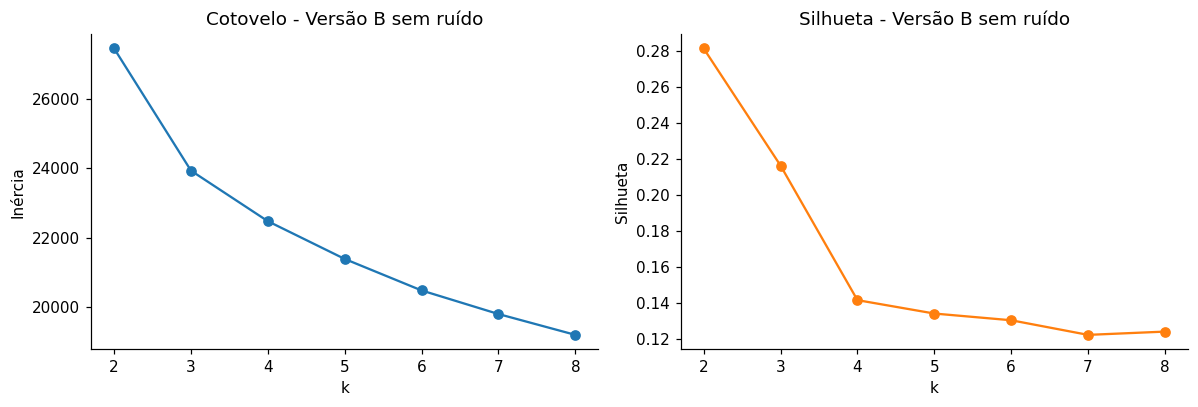

   k  silhueta_com_ruido  silhueta_sem_ruido
0  2               0.268               0.281
1  3               0.203               0.216
2  4               0.132               0.141
3  5               0.124               0.134
4  6               0.125               0.130
5  7               0.124               0.122
6  8               0.099               0.124


,Income,Idade,Filhos,Gasto_Total
Seg_sem_ruido,,,,
0,75129.2,45.8,0.2,1339.2
1,34491.7,42.1,1.2,94.2
2,57436.9,49.6,1.2,711.5


In [13]:
# A - sem os clientes ruído
mask = labels_db != -1
res_A2 = avaliar_k(X_B[mask], "Versão B sem ruído")
comp = pd.DataFrame({"k": res_B["k"], "silhueta_com_ruido": res_B["silhueta"].values,
                     "silhueta_sem_ruido": res_A2["silhueta"].values}).round(3)
print(comp)

k_a = k
m_a = make_pipeline(StandardScaler(), KMeans(n_clusters=k_a, n_init=10, random_state=42)).fit(X_B[mask])
p_a = p[mask].copy(); p_a["Seg_sem_ruido"] = m_a.predict(X_B[mask])
p_a.groupby("Seg_sem_ruido")[["Income", "Idade", "Filhos", "Gasto_Total"]].mean().round(1)
# Análise: a silhueta tende a subir sem os outliers, e as médias (principalmente renda) ficam mais representativas.

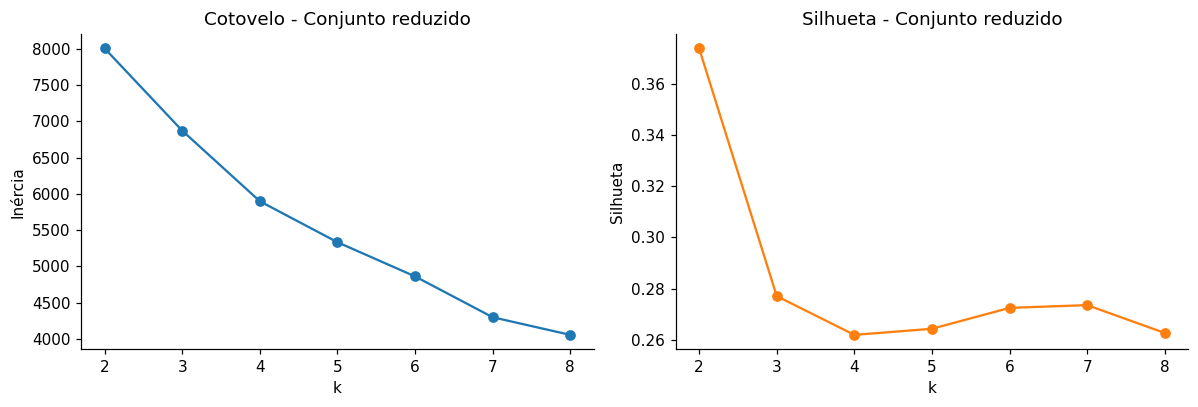

   k  sil_B  sil_reduzido
0  2  0.268         0.374
1  3  0.203         0.277
2  4  0.132         0.262
3  5  0.124         0.264
4  6  0.125         0.273
5  7  0.124         0.274
6  8  0.099         0.263


In [14]:
# B - conjunto reduzido
X_R = pd.DataFrame({
    "Income": p["Income"],
    "Idade": p["Idade"],
    "Filhos": p["Filhos"],
    "Gasto_Total": p["Gasto_Total"],
    "Total_Compras": p[["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]].sum(axis=1),
    "Visitas_Site": p["NumWebVisitsMonth"],
})
res_R = avaliar_k(X_R, "Conjunto reduzido")
print(pd.DataFrame({"k": res_R["k"], "sil_B": res_B["silhueta"].values, "sil_reduzido": res_R["silhueta"]}).round(3))
# Vantagem: só 6 entradas no deploy, mais simples de coletar/validar, menos risco de erro e mais fácil de explicar.

In [15]:
# C - k = 4
modelo4 = make_pipeline(StandardScaler(), KMeans(n_clusters=4, n_init=10, random_state=42)).fit(X_B)
p["Seg4"] = modelo4.predict(X_B)
perfil4 = p.groupby("Seg4").agg(
    Clientes=("Income", "size"), Renda=("Income", "mean"), Idade=("Idade", "mean"),
    Filhos=("Filhos", "mean"), Gasto_Total=("Gasto_Total", "mean"), Gasto_Vinhos=("MntWines", "mean"),
    Compras_Desconto=("NumDealsPurchases", "mean"), Visitas_Site=("NumWebVisitsMonth", "mean"),
).round(2)
display(perfil4)
display(pd.crosstab(p["Segmento"], p["Seg4"]))  # mostra qual segmento foi subdividido
# Análise: ver na crosstab qual segmento original se dividiu em dois e se os perfis novos diferem o suficiente para campanhas distintas.

,Clientes,Renda,Idade,Filhos,Gasto_Total,Gasto_Vinhos,Compras_Desconto,Visitas_Site
Seg4,,,,,,,,
0,577,29630.95,35.98,0.85,100.62,33.45,1.90,6.94
1,586,76538.68,45.59,0.21,1353.57,582.56,1.31,2.79
2,538,58881.98,49.22,1.12,812.28,522.38,3.77,5.81
3,539,43387.45,50.61,1.69,127.52,72.53,2.44,5.84


Seg4,0,1,2,3
Segmento,,,,
0,571,1,0,470
1,0,585,10,0
2,6,0,528,69
